*Ana Rosa Pérez y Albert Pineda*

## Proyecto APA Evaluación preliminar

# Predicción de Insuficiencia cardíaca crónica tras infarto de miocardio 

El conjunto de datos que hemos seleccionado es: https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications , **complicaciones de infarto de miocardio**. Este conjunto estudia varios pacientes en donde algunos han sufrido infarto de miocardios (o varios) y busca predecir las complicaciones que se pueden sufrir.

Las complicaciones que nos indica la web del dataset junto al número de casos positivos son las siguientes:

| Variable objetivo | Complicación / desenlace | Casos negativos (0) | Casos positivos (1) | % positivos |
|---|---|---:|---:|---|
| FIBR_PREDS | Fibrilación auricular | 1530 | 170 | 10.00% |
| PREDS_TAH | Taquicardia supraventricular | 1680 | 20 | 1.18% | 
| JELUD_TAH | Taquicardia ventricular | 1658 | 42 | 2.47% | 
| FIBR_JELUD | Fibrilación ventricular | 1629 | 71 | 4.18% | 
| A_V_BLOK | Bloqueo AV de tercer grado | 1643 | 57 | 3.35% | 
| OTEK_LANC | Edema pulmonar | 1541 | 159 | 9.35% | 
| RAZRIV | Rotura miocárdica | 1646 | 54 | 3.18% | 
| DRESSLER | Síndrome de Dressler | 1625 | 75 | 4.41% | 
| ZSN | Insuficiencia cardíaca crónica | 1306 | 394 | 23.18% | 
| REC_IM | Recaída del infarto de miocardio | 1541 | 159 | 9.35% |
| P_IM_STEN | Angina posterior al infarto | 1552 | 148 | 8.71% | 
| LET_IS | Desenlace mortal (causa) | 1429* | 271* | 15.94%* |

Con esta tabla, decidimos que la variable a estudiar por el momento es la Insuficiencia cardíaca cronica (ZSN). Como esta es una variable binaria, nuestro trabajo será de **clasificación**. El problema que seleccionamos a través de este dataset será: **predecir Insuficiencia cardíaca crónica tras infarto de miocardio** .

### Atributos asociados con el tiempo
En estos datos tenemos bastantes variables que tienen que ver con el tiempo y que pueden ser razonables o no para lo que nos interesa estudiar y en qué momento queremos predecir. Por ejemplo, no podemos utilizar una variable de *medicina dada el tercer dia tras el ingreso* si nuestro modelo predice desde el día que el paciente es ingresado. Las variables relacionadas al tiempo junto su información temporal son:

| Variable | Significado | Tipo de información temporal |
|---|---|---|
| TIME_B_S | Tiempo transcurrido desde el inicio del episodio coronario hasta la llegada al hospital. | Tiempo previo al ingreso |
| STENOK_AN | Antecedentes de angina de esfuerzo y cuándo se produjeron. | Historial clínico |
| DLIT_AG | Duración de la hipertensión arterial. | Duración de una enfermedad previa |
| IBS_POST | Presencia y tipo de enfermedad coronaria en los días o semanas anteriores al ingreso. | Historial clínico reciente |
| R_AB_1_n | Número de recaídas del dolor durante las primeras horas de hospitalización. | Evolución hospitalaria inicial |
| R_AB_2_n | Número de recaídas del dolor durante el segundo día de hospitalización. | Evolución hospitalaria, día 2 |
| R_AB_3_n | Número de recaídas del dolor durante el tercer día de hospitalización. | Evolución hospitalaria, día 3 |
| NA_R_1_n | Uso de opioides en la unidad de cuidados intensivos durante las primeras horas. | Tratamiento hospitalario inicial |
| NA_R_2_n | Uso de opioides en la unidad de cuidados intensivos durante el segundo día. | Tratamiento hospitalario, día 2 |
| NA_R_3_n | Uso de opioides en la unidad de cuidados intensivos durante el tercer día. | Tratamiento hospitalario, día 3 |
| NOT_NA_1_n | Uso de antiinflamatorios no esteroideos durante las primeras horas en cuidados intensivos. | Tratamiento hospitalario inicial |
| NOT_NA_2_n | Uso de antiinflamatorios no esteroideos durante el segundo día en cuidados intensivos. | Tratamiento hospitalario, día 2 |
| NOT_NA_3_n | Uso de antiinflamatorios no esteroideos durante el tercer día en cuidados intensivos. | Tratamiento hospitalario, día 3 |

Consideramos que es más útil realizar un predictor utilizado en el **momento del ingreso**, es por eso que las variables de tratamiento hospitalario las eliminaremos, ya que describen algo que aún no habría ocurrido.



### Desbalance entre clases

La variable objetivo `ZSN` representa la presencia o ausencia de insuficiencia cardíaca crónica.

Según la distribución del dataset, hay 394 pacientes positivos y 1.306 negativos, sobre un total de 1.700 pacientes:

| Clase | Significado | Número de pacientes | Porcentaje |
|---|---|---:|---:|
| 0 | Sin insuficiencia cardíaca crónica | 1.306 | 76,82 % |
| 1 | Con insuficiencia cardíaca crónica | 394 | 23,18 % |
| **Total** | | **1.700** | **100 %** |

Existe, por tanto, un desbalance moderado entre las clases. No es un desequilibrio extremo, pero sí suficientemente importante como para tenerlo en cuenta al entrenar y evaluar el modelo. El problema es que el modelo pueda convertirse extremadamente positivo y que apenas sea capaz de detectar casos de insuficiencia cardiaca crónica.

Durante el preprocesamiento se conservará la distribución de clases y se utilizará una partición estratificada para mantener proporciones similares de ambas clases en los conjuntos de entrenamiento y prueba. Si fuera necesario aplicar técnicas de sobremuestreo o submuestreo, estas se realizarán únicamente sobre los datos de entrenamiento.

Además vemos que el conjunto presenta en casi todas las variables valores perdidos, por lo que tendremos que imputar esos datos.

### Obtención de los datos

Utilizamos la función de importación proporcionada por el repositorio de UC Irvine

In [29]:
pip install ucimlrepo

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

# Cargar dataset
myocardial_infarction_complications = fetch_ucirepo(id=579)

X = myocardial_infarction_complications.data.features
y = myocardial_infarction_complications.data.targets

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

display(X.head())
display(y.head())

Dimensiones de X: (1700, 111)
Dimensiones de y: (1700, 12)


,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,IBS_NASL,GB,SIM_GIPERT,DLIT_AG,...,NOT_NA_1_n,NOT_NA_2_n,NOT_NA_3_n,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n
0,77.0,1,2.0,1.0,1.0,2.0,NaN,3.0,0.0,7.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0
1,55.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0
2,52.0,1,0.0,0.0,0.0,2.0,NaN,2.0,0.0,2.0,...,3.0,2.0,2.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0
3,68.0,0,0.0,0.0,0.0,2.0,NaN,2.0,0.0,3.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0
4,60.0,1,0.0,0.0,0.0,2.0,NaN,3.0,0.0,7.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0


,FIBR_PREDS,PREDS_TAH,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,1,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0


In [31]:
TARGET = "ZSN"
df = X.copy().reset_index(drop=True)

# Añadir el target al DataFrame auxiliar
df[TARGET] = pd.to_numeric(
    y[TARGET].reset_index(drop=True),
    errors="coerce"
)

# Eliminar el identificador: no tiene significado clínico predictivo
df = df.drop(columns=["ID"], errors="ignore")

# Revisar la distribución del target
print("Distribución de ZSN:")
display(
    df[TARGET]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("ZSN")
    .to_frame("Número de pacientes")
)

print("\nValores ausentes en ZSN:", df[TARGET].isna().sum())

Distribución de ZSN:


,Número de pacientes
ZSN,
0,1306
1,394



Valores ausentes en ZSN: 0


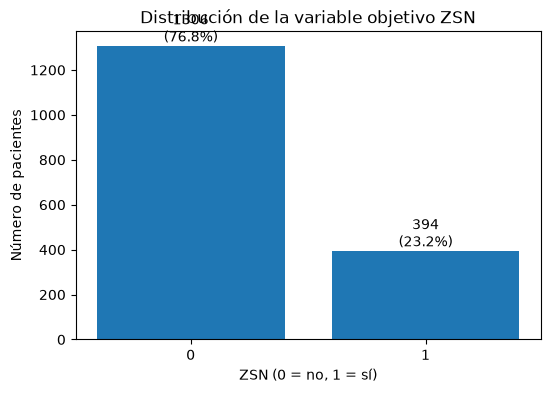

In [32]:
counts = df[TARGET].value_counts().sort_index()
percentages = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    counts.index.astype(str),
    counts.values
)

ax.set_title("Distribución de la variable objetivo ZSN")
ax.set_xlabel("ZSN (0 = no, 1 = sí)")
ax.set_ylabel("Número de pacientes")

for bar, count, percentage in zip(
    bars, counts.values, percentages.values
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.show()

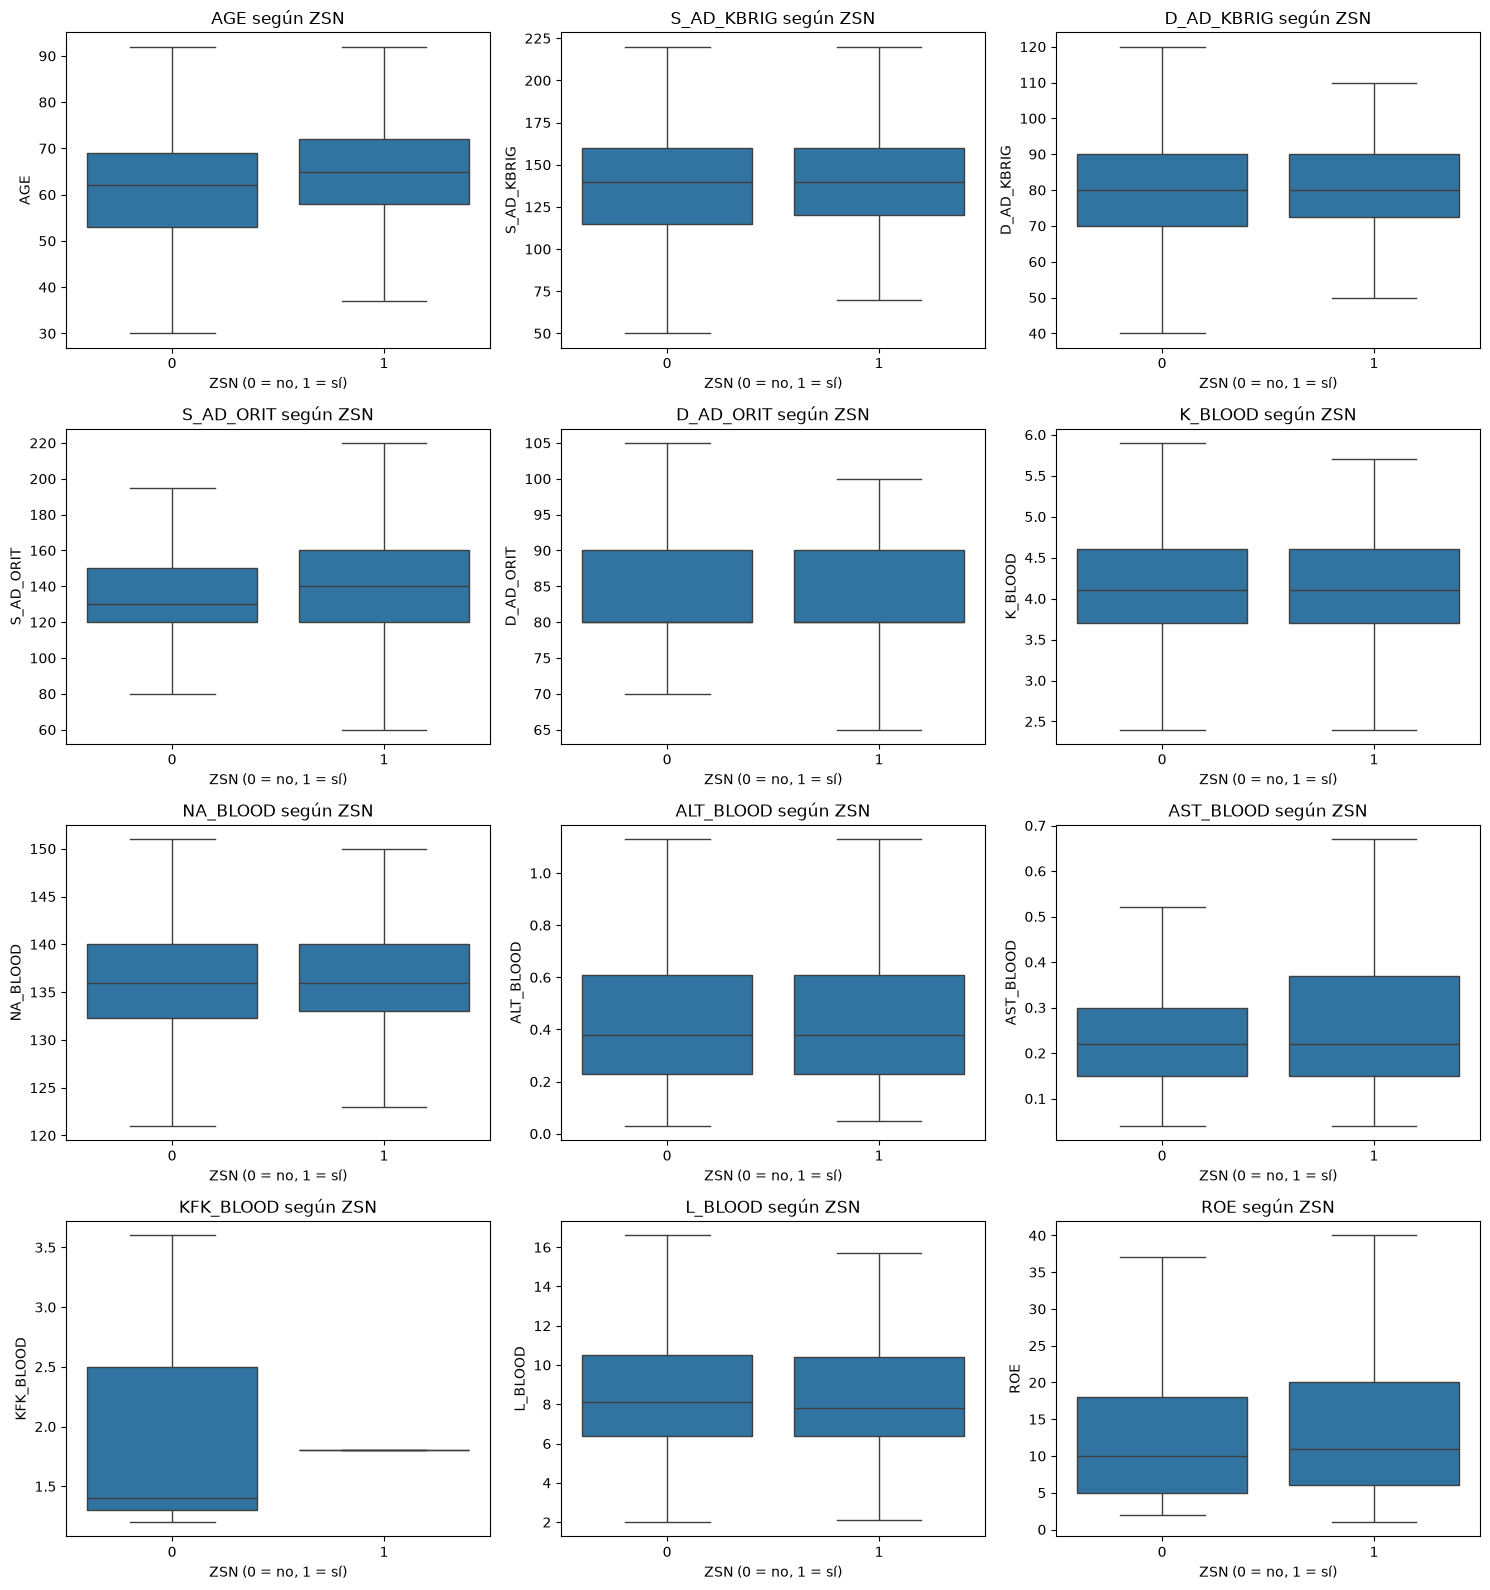

In [33]:
# Variables cuantitativas de interés clínico
numeric_candidates = [
    "AGE",
    "S_AD_KBRIG",
    "D_AD_KBRIG",
    "S_AD_ORIT",
    "D_AD_ORIT",
    "K_BLOOD",
    "NA_BLOOD",
    "ALT_BLOOD",
    "AST_BLOOD",
    "KFK_BLOOD",
    "L_BLOOD",
    "ROE"
]

# Convertirlas a formato numérico
for col in numeric_candidates:
    df[col] = pd.to_numeric(df[col], errors="coerce")

ncols = 3
nrows = int(np.ceil(len(numeric_candidates) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(15, 4 * nrows)
)

axes = np.asarray(axes).flatten()

for ax, col in zip(axes, numeric_candidates):
    sns.boxplot(
        data=df,
        x=TARGET,
        y=col,
        showfliers=False,
        ax=ax
    )

    ax.set_title(f"{col} según ZSN")
    ax.set_xlabel("ZSN (0 = no, 1 = sí)")
    ax.set_ylabel(col)

# Ocultar los ejes sobrantes
for ax in axes[len(numeric_candidates):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

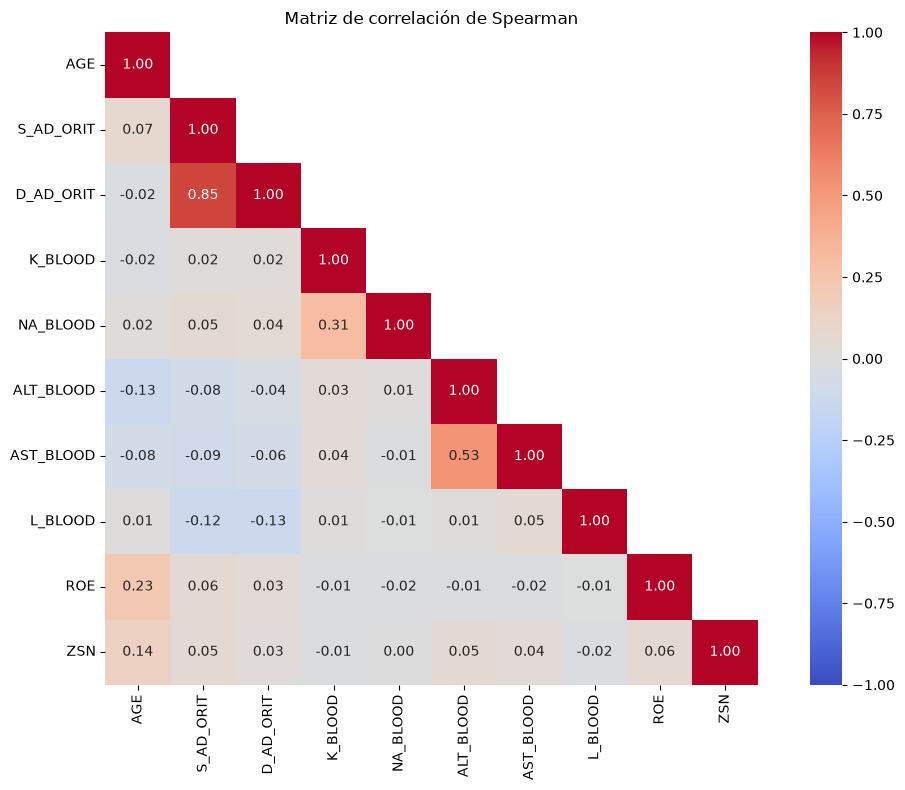

In [34]:
# Variables cuantitativas candidatas
corr_candidates = [
    "AGE",
    "S_AD_KBRIG",
    "D_AD_KBRIG",
    "S_AD_ORIT",
    "D_AD_ORIT",
    "K_BLOOD",
    "NA_BLOOD",
    "ALT_BLOOD",
    "AST_BLOOD",
    "KFK_BLOOD",
    "L_BLOOD",
    "ROE"
]

# Conservar las existentes con suficientes datos observados
corr_cols = [
    col for col in corr_candidates
    if col in df.columns
    and df[col].notna().mean() >= 0.40
]

# Añadir el objetivo para explorar asociaciones con ZSN
corr_df = df[corr_cols + [TARGET]].copy()
corr_df = corr_df.apply(pd.to_numeric, errors="coerce").astype(float)

corr_matrix = corr_df.corr(method="spearman")

# Mostrar únicamente la mitad inferior para facilitar la lectura
mask = np.triu(
    np.ones_like(corr_matrix, dtype=bool),
    k=1
)

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Matriz de correlación de Spearman")
plt.tight_layout()
plt.show()

Variables categóricas: 98
Variables cuantitativas: 9
Variables excluidas por valores ausentes: 4


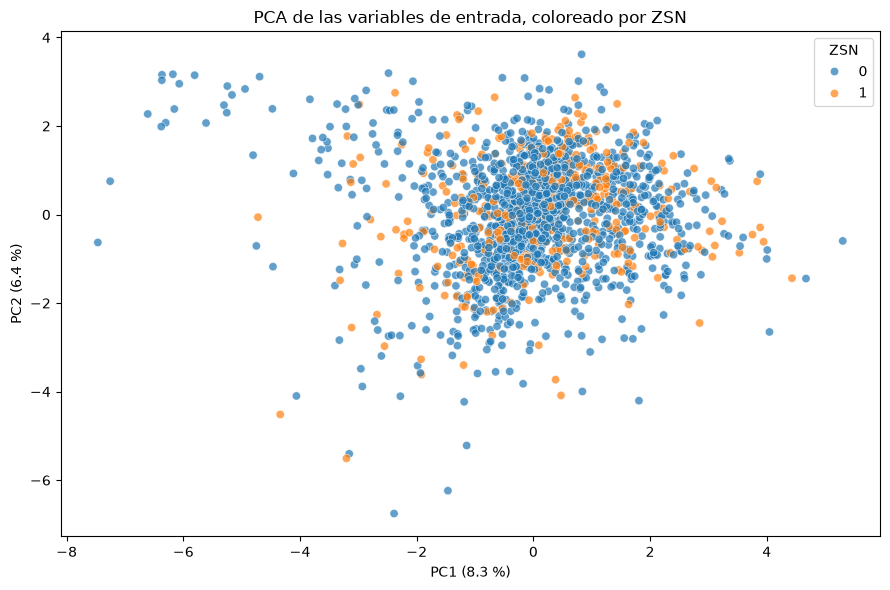

Varianza explicada por los dos componentes: 14.65 %


In [37]:
#
#
# HECHO CON IA, REVISAR !!! Hace muchos pasos de preprocesado para hacer el PCA. Lo he puesto para poder visualizar los datos mejor.
#
#


from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

# Preparar SOLO las variables de entrada, sin incluir ZSN
X_pca = (
    X.copy()
    .reset_index(drop=True)
    .drop(columns=["ID"], errors="ignore")
    .apply(pd.to_numeric, errors="coerce")
)

# Excluir columnas con más de un 60 % de valores ausentes
missing_fraction = X_pca.isna().mean()
X_pca = X_pca.loc[:, missing_fraction <= 0.60]

# Heurística para separar categorías codificadas y variables cuantitativas
n_unique = X_pca.nunique(dropna=True)

categorical_cols = n_unique[n_unique <= 10].index.tolist()
numeric_cols = n_unique[n_unique > 10].index.tolist()

print("Variables categóricas:", len(categorical_cols))
print("Variables cuantitativas:", len(numeric_cols))
print("Variables excluidas por valores ausentes:",
      (missing_fraction > 0.60).sum())

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

transformers = []

if numeric_cols:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numeric_cols)
    )

if categorical_cols:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder)
    ])

    transformers.append(
        ("categorical", categorical_pipeline, categorical_cols)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    sparse_threshold=0
)

# Transformar las variables sin utilizar el target como predictor
X_encoded = preprocessor.fit_transform(X_pca)

# Reducir a dos componentes principales
pca = PCA(n_components=2, random_state=42)
X_pca_2d = pca.fit_transform(X_encoded)

pca_df = pd.DataFrame(
    X_pca_2d,
    columns=["PC1", "PC2"]
)

# Utilizar ZSN únicamente para colorear los puntos
pca_df[TARGET] = df[TARGET].astype(str).values

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue=TARGET,
    alpha=0.7
)

plt.title("PCA de las variables de entrada, coloreado por ZSN")
plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f} %)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f} %)"
)

plt.tight_layout()
plt.show()

print(
    "Varianza explicada por los dos componentes: "
    f"{pca.explained_variance_ratio_.sum() * 100:.2f} %"
)

La proyección de las dos primeras componentes principales explica el 14,7 % de la varianza total y no muestra una separación visual clara entre las clases de ZSN. Sin embargo, esto no permite descartar la existencia de patrones predictivos en dimensiones adicionales o mediante combinaciones no lineales de variables.